# Introduction

The final Python EDA focused on exploring the dataset, identifying patterns, validating key findings, and extracting insights to support data driven business decisions.

## Objectives

* Examine data quality and handle missing values and inconsistencies.
* Explore distributions, trends, and relationships between variables.
* Identify key patterns and validate business findings.
* Present insights through visualizations and provide actionable recommendations.

In [38]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [53]:
transactions = pd.read_csv('transactions')
customers = pd.read_csv('customers')

In [40]:
transactions["Transaction_DateTime"] = pd.to_datetime(transactions["Transaction_DateTime"])

## Customer Engagement and Behaviour by Segment

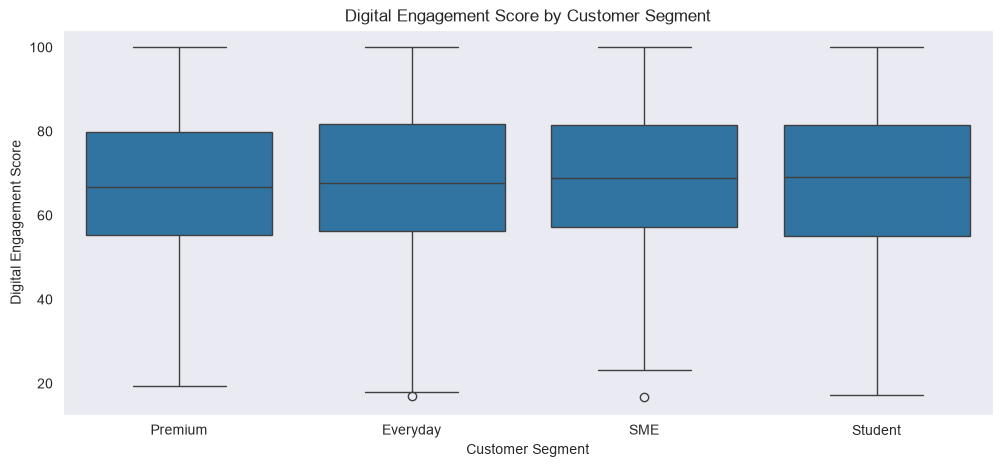

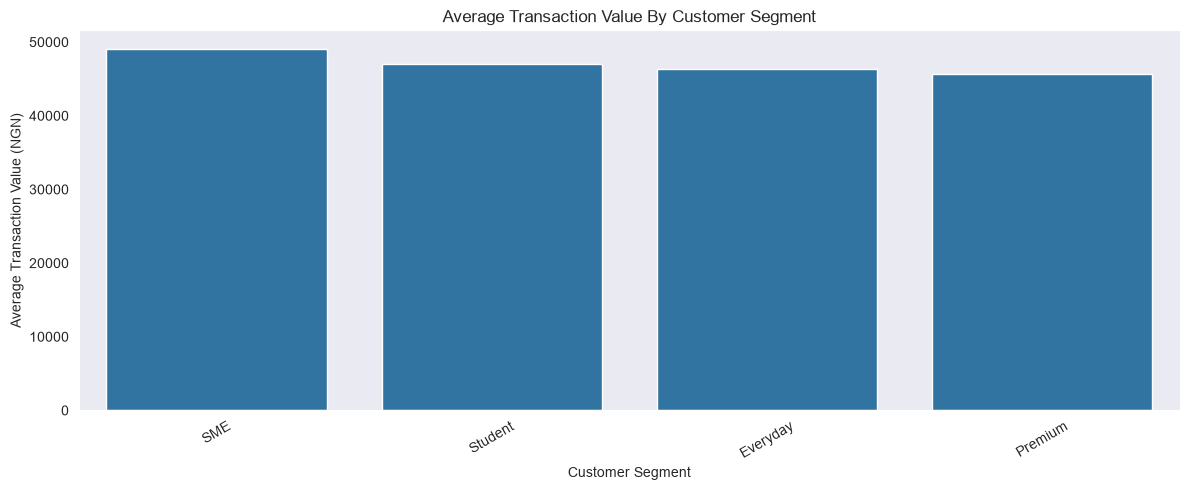

,Customers,Average_Engagement,Average_Transactions,Average_Total_Value
Customer_Segment,,,,
Everyday,711,68.37,7.94,367734.07
Premium,295,66.71,8.00,365258.29
SME,216,68.34,7.90,387923.02
Student,278,67.91,8.23,386603.84


In [55]:
customer_activity = (
    transactions.groupby("Customer_ID")
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Total_Transaction_Value=("Amount_NGN", "sum"),
        Average_Transaction_Value=("Amount_NGN", "mean")
    )
    .reset_index()
)

customer_analysis = customers.merge(
    customer_activity,
    on="Customer_ID",
    how="left"
)

customer_analysis['Transaction_Count'] = (
    customer_analysis['Transaction_Count'].fillna(0)
)

customer_analysis['Total_Transaction_Value'] = (
    customer_analysis['Total_Transaction_Value'].fillna(0)
)

plt.figure(figsize=(12,5))
sns.boxplot(
    data=customer_analysis,
    x='Customer_Segment',
    y='Digital_Engagement_Score'
)
plt.title("Digital Engagement Score by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Digital Engagement Score")
plt.show()

segment_values = (
    transactions.merge(
        customers[['Customer_ID', 'Customer_Segment']],
        on='Customer_ID',
        how='left'
    )
    .groupby('Customer_Segment')['Amount_NGN']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12,5))
sns.barplot(x=segment_values.index, y=segment_values.values)
plt.title("Average Transaction Value By Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Transaction Value (NGN)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(
    customer_analysis.groupby("Customer_Segment")
    .agg(
        Customers=("Customer_ID", "nunique"),
        Average_Engagement=("Digital_Engagement_Score", "mean"),
        Average_Transactions=("Transaction_Count", "mean"),
        Average_Total_Value=("Total_Transaction_Value", "mean")
    )
    .round(2)
)

## Transaction Amount Distribution and High-Value Transactions

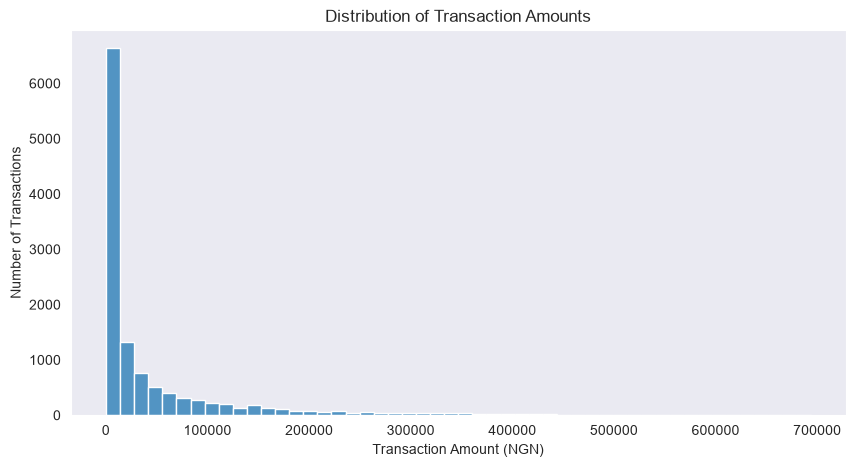

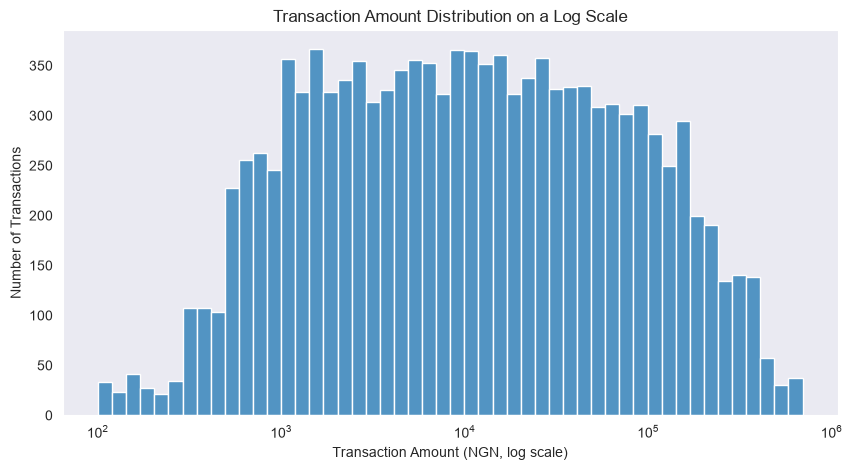

,Transaction_Count,Total_Value,Average_Value
Transaction_Type,,,
Transfer,718,1.761903e+08,245390.35
Deposit,344,1.077435e+08,313207.86
Cash Withdrawal,209,3.631795e+07,173770.10
Card Purchase,203,2.988171e+07,147200.54


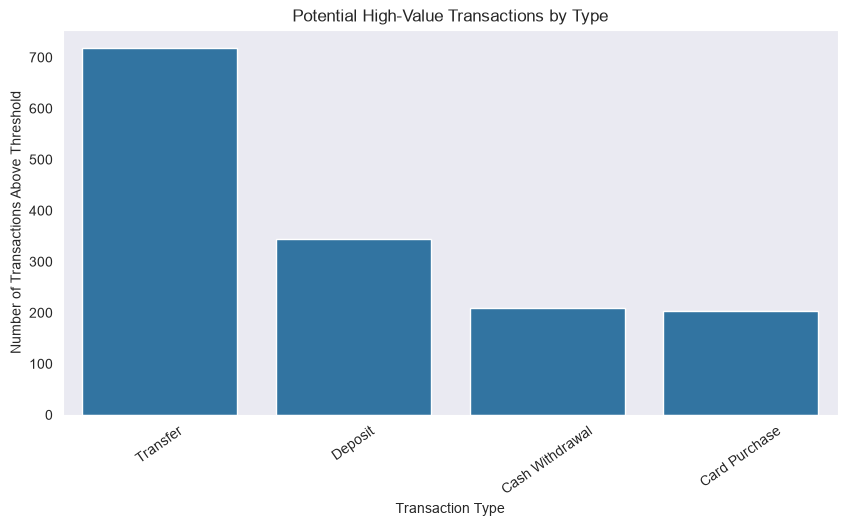

In [56]:
# Transaction amount distribution
plt.figure(figsize=(10, 5))
sns.histplot(
    data=transactions,
    x="Amount_NGN",
    bins=50
)
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount (NGN)")
plt.ylabel("Number of Transactions")
plt.show()

# Log scale helps reveal the distribution of smaller values
plt.figure(figsize=(10, 5))
sns.histplot(
    data=transactions,
    x="Amount_NGN",
    bins=50,
    log_scale=(True, False)
)
plt.title("Transaction Amount Distribution on a Log Scale")
plt.xlabel("Transaction Amount (NGN, log scale)")
plt.ylabel("Number of Transactions")
plt.show()

# Use the Week 2 IQR upper threshold
upper_bound = 117922.86

high_value = transactions[
    transactions["Amount_NGN"] > upper_bound
].copy()

# Summarise high-value transactions by type
high_value_summary = (
    high_value.groupby("Transaction_Type")
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Total_Value=("Amount_NGN", "sum"),
        Average_Value=("Amount_NGN", "mean")
    )
    .sort_values("Transaction_Count", ascending=False)
)

display(high_value_summary.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(
    data=high_value_summary.reset_index(),
    x="Transaction_Type",
    y="Transaction_Count"
)
plt.title("Potential High-Value Transactions by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions Above Threshold")
plt.xticks(rotation=35)
plt.show()

## Transaction Channel Performance

,Transaction_Count,Total_Value,Average_Value,Successful_Transactions,Success_Rate
Channel,,,,,
Mobile App,5102,2.401044e+08,47060.83,4579,89.75
POS,2393,1.043467e+08,43604.96,2174,90.85
Web,1869,8.932500e+07,47792.94,1698,90.85
ATM,1747,8.394235e+07,48049.43,1602,91.70
USSD,889,4.275895e+07,48097.81,803,90.33


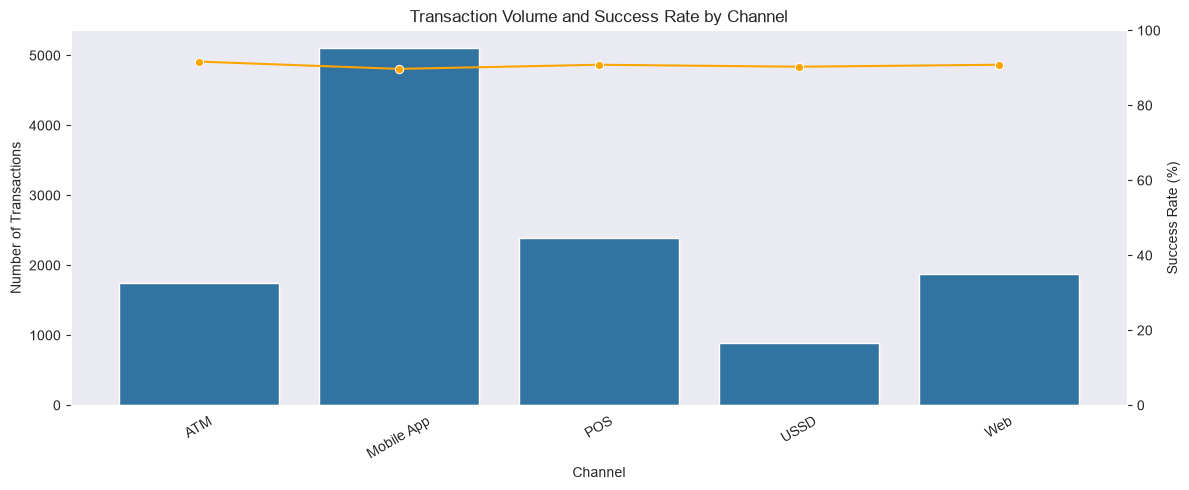

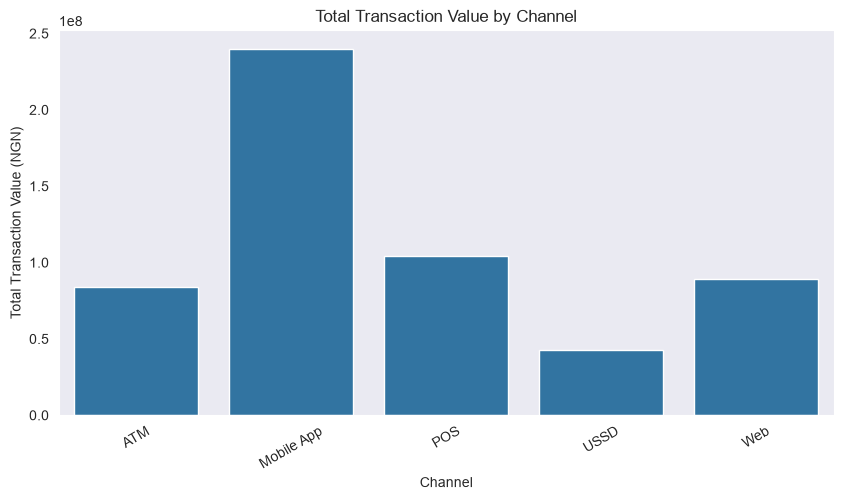

In [57]:
channel_summary = (
    transactions.assign(
        Successful=transactions["Transaction_Status"].eq("Successful")
    )
    .groupby("Channel")
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Total_Value=("Amount_NGN", "sum"),
        Average_Value=("Amount_NGN", "mean"),
        Successful_Transactions=("Successful", "sum")
    )
)

channel_summary["Success_Rate"] = (
    channel_summary["Successful_Transactions"]
    / channel_summary["Transaction_Count"] * 100
)

display(channel_summary.sort_values(
    "Transaction_Count", ascending=False
).round(2))

# Plot transaction volume and success rate together
fig, ax1 = plt.subplots()
fig.set_size_inches(12, 5)

sns.barplot(
    x=channel_summary.index,
    y=channel_summary["Transaction_Count"],
    ax=ax1
)
ax1.set_xlabel("Channel")
ax1.set_ylabel("Number of Transactions")
ax1.tick_params(axis="x", rotation=30)

ax2 = ax1.twinx()
sns.lineplot(
    x=channel_summary.index,
    y=channel_summary["Success_Rate"],
    marker="o",
    color="orange",
    ax=ax2
)
ax2.set_ylabel("Success Rate (%)")
ax2.set_ylim(0, 100)

plt.title("Transaction Volume and Success Rate by Channel")
plt.tight_layout()
plt.show()

# Total transaction value by channel
plt.figure(figsize=(10, 5))
sns.barplot(
    x=channel_summary.index,
    y=channel_summary["Total_Value"]
)
plt.title("Total Transaction Value by Channel")
plt.xlabel("Channel")
plt.ylabel("Total Transaction Value (NGN)")
plt.xticks(rotation=30)
plt.show()

## Monthly Transaction Performance and Trends

,Total_Transactions,Successful_Transactions,Total_Value,Average_Value,Success_Rate
Transaction_DateTime,,,,,
2026-01-31,4133,3720,1.884894e+08,45605.96,90.01
2026-02-28,3734,3394,1.757869e+08,47077.37,90.89
2026-03-31,4133,3742,1.962010e+08,47471.82,90.54


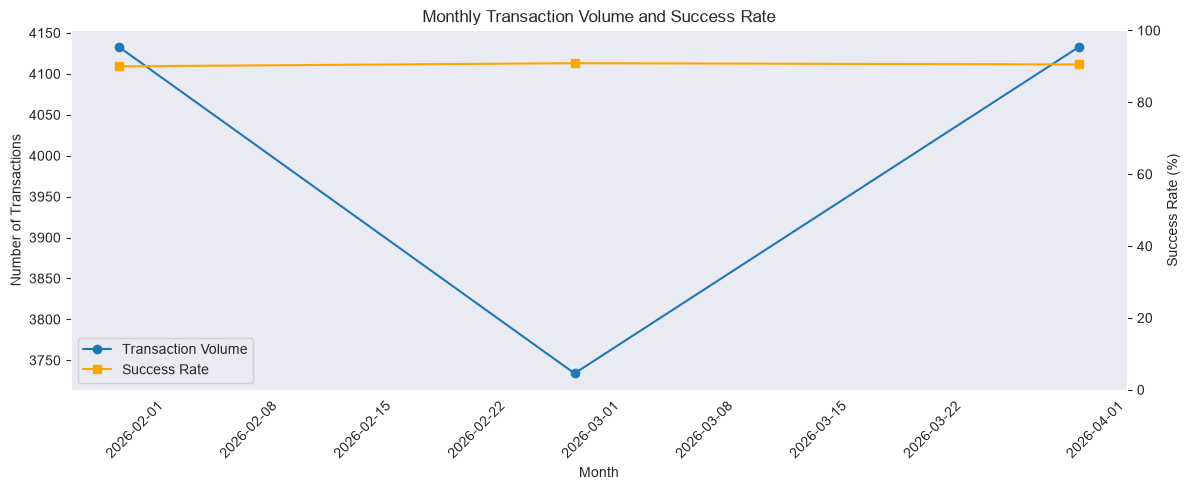

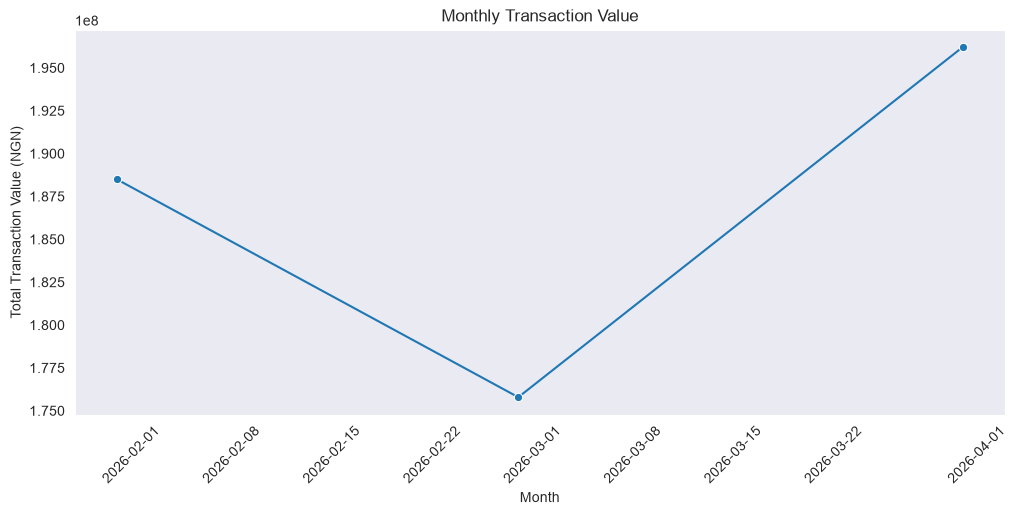

In [58]:
transactions["Transaction_DateTime"] = pd.to_datetime(
    transactions["Transaction_DateTime"],
    errors="coerce"
)

monthly_performance = (
    transactions.dropna(subset=["Transaction_DateTime"])
    .set_index("Transaction_DateTime")
    .resample("ME")
    .agg(
        Total_Transactions=("Transaction_ID", "count"),
        Successful_Transactions=(
            "Transaction_Status",
            lambda x: x.eq("Successful").sum()
        ),
        Total_Value=("Amount_NGN", "sum"),
        Average_Value=("Amount_NGN", "mean")
    )
)

monthly_performance["Success_Rate"] = (
    monthly_performance["Successful_Transactions"]
    / monthly_performance["Total_Transactions"] * 100
)

display(monthly_performance.round(2))

# Plot monthly transaction volume and success rate
fig, ax1 = plt.subplots()
fig.set_size_inches(12, 5)

ax1.plot(
    monthly_performance.index,
    monthly_performance["Total_Transactions"],
    marker="o",
    label="Transaction Volume"
)
ax1.set_xlabel("Month")
ax1.set_ylabel("Number of Transactions")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(
    monthly_performance.index,
    monthly_performance["Success_Rate"],
    marker="s",
    color="orange",
    label="Success Rate"
)
ax2.set_ylabel("Success Rate (%)")
ax2.set_ylim(0, 100)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.title("Monthly Transaction Volume and Success Rate")
plt.tight_layout()
plt.show()

# Monthly transaction value
plt.figure(figsize=(12, 5))
sns.lineplot(
    x=monthly_performance.index,
    y=monthly_performance["Total_Value"],
    marker="o"
)
plt.title("Monthly Transaction Value")
plt.xlabel("Month")
plt.ylabel("Total Transaction Value (NGN)")
plt.xticks(rotation=45)
plt.show()

## Risk Review Patterns by Transaction Type and International Status

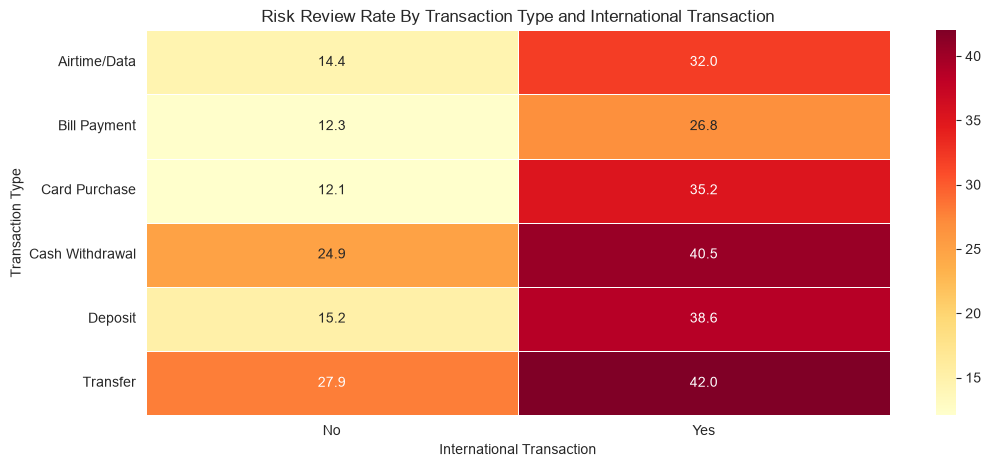

In [60]:
risk_comparison = (
    transactions.pivot_table(
        values = 'Risk_Review_Flag',
        index = 'Transaction_Type',
        columns = 'International_Transaction',
        aggfunc = lambda x: x.eq('Yes').mean() * 100
            )
)

plt.figure(figsize=(12,5))
sns.heatmap(
    risk_comparison,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)
plt.title("Risk Review Rate By Transaction Type and International Transaction")
plt.xlabel("International Transaction")
plt.ylabel("Transaction Type")
plt.show()

## Risk Review by Customer Segment

,Transaction_Count,Risk_Reviews,Risk_Review_Rate
Customer_Segment,,,
Premium,2361,480,20.33
Student,2289,452,19.75
SME,1706,331,19.40
Everyday,5644,1089,19.29


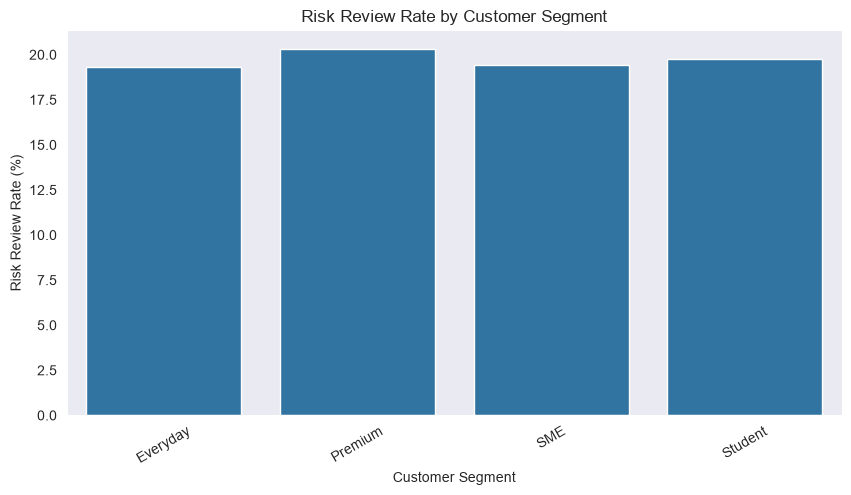

In [61]:
risk_customer = transactions.merge(
    customers[["Customer_ID", "Customer_Segment"]],
    on="Customer_ID",
    how="left"
)

segment_risk = (
    risk_customer.groupby("Customer_Segment")
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Risk_Reviews=(
            "Risk_Review_Flag",
            lambda x: x.astype(str).str.strip().eq("Yes").sum()
        )
    )
)

segment_risk["Risk_Review_Rate"] = (
    segment_risk["Risk_Reviews"]
    / segment_risk["Transaction_Count"] * 100
)

display(segment_risk.sort_values(
    "Risk_Review_Rate", ascending=False
).round(2))

plt.figure(figsize=(10, 5))
sns.barplot(
    x=segment_risk.index,
    y=segment_risk["Risk_Review_Rate"]
)
plt.title("Risk Review Rate by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Risk Review Rate (%)")
plt.xticks(rotation=30)
plt.show()

## Customer-Level Transaction Frequency and Value

,Customer_ID,Transaction_Count,Total_Transaction_Value,Average_Transaction_Value,Customer_Segment
1074,FT-C01075,10,1713942.51,171394.25,Everyday
356,FT-C00357,18,1713516.28,95195.35,Everyday
815,FT-C00816,17,1611209.24,94777.01,Everyday
689,FT-C00690,12,1522279.61,126856.63,SME
22,FT-C00023,11,1440772.53,130979.32,Student
106,FT-C00107,15,1386146.39,92409.76,Everyday
30,FT-C00031,10,1354111.51,135411.15,Premium
725,FT-C00726,11,1347878.51,122534.41,Everyday
1329,FT-C01330,10,1333820.19,133382.02,Everyday
398,FT-C00399,16,1318642.71,82415.17,Premium


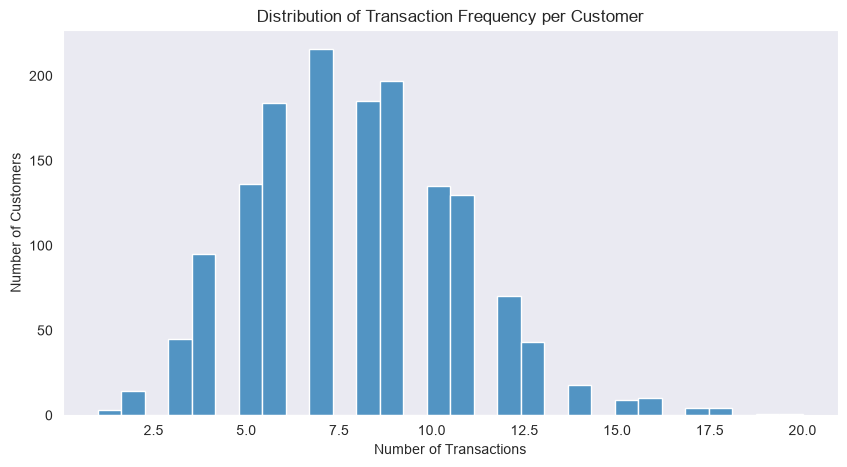

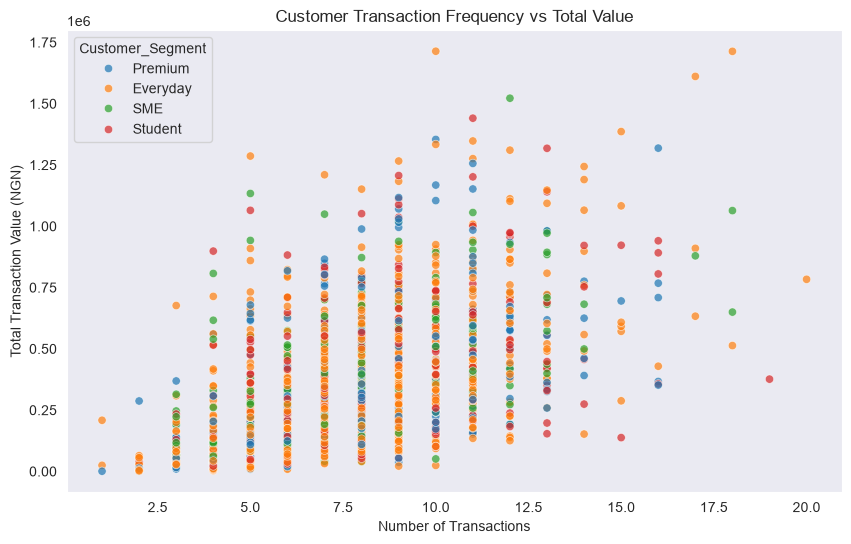

,Customers,Average_Transactions,Average_Total_Value,Average_Transaction_Value
Customer_Segment,,,,
Everyday,711,7.94,367734.07,45730.88
Premium,295,8.00,365258.29,44524.67
SME,216,7.90,387923.02,49391.25
Student,278,8.23,386603.84,47120.04


In [62]:
customer_activity = (
    transactions.groupby("Customer_ID")
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Total_Transaction_Value=("Amount_NGN", "sum"),
        Average_Transaction_Value=("Amount_NGN", "mean")
    )
    .reset_index()
    .merge(
        customers[["Customer_ID", "Customer_Segment"]],
        on="Customer_ID",
        how="left"
    )
)

display(
    customer_activity.sort_values(
        "Total_Transaction_Value", ascending=False
    ).head(10).round(2)
)

# Distribution of transaction counts per customer
plt.figure(figsize=(10, 5))
sns.histplot(
    data=customer_activity,
    x="Transaction_Count",
    bins=30
)
plt.title("Distribution of Transaction Frequency per Customer")
plt.xlabel("Number of Transactions")
plt.ylabel("Number of Customers")
plt.show()

# Transaction frequency against total transaction value
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=customer_activity,
    x="Transaction_Count",
    y="Total_Transaction_Value",
    hue="Customer_Segment",
    alpha=0.7
)
plt.title("Customer Transaction Frequency vs Total Value")
plt.xlabel("Number of Transactions")
plt.ylabel("Total Transaction Value (NGN)")
plt.show()

# Summary by customer segment
display(
    customer_activity.groupby("Customer_Segment")
    .agg(
        Customers=("Customer_ID", "nunique"),
        Average_Transactions=("Transaction_Count", "mean"),
        Average_Total_Value=("Total_Transaction_Value", "mean"),
        Average_Transaction_Value=("Average_Transaction_Value", "mean")
    )
    .round(2)
)

## Validation of Key Week 2 Findings

In [63]:
# Overall transaction success rate
total_transactions = transactions["Transaction_ID"].count()

successful_transactions = (
    transactions["Transaction_Status"].eq("Successful").sum()
)

success_rate = successful_transactions / total_transactions * 100

# Overall risk review rate
risk_reviews = (
    transactions["Risk_Review_Flag"]
    .astype(str).str.strip().eq("Yes").sum()
)

risk_review_rate = risk_reviews / total_transactions * 100

print(f"Total customers: {customers['Customer_ID'].nunique():,}")
print(f"Total transactions: {total_transactions:,}")
print(f"Successful transactions: {successful_transactions:,}")
print(f"Transaction success rate: {success_rate:.2f}%")
print(f"Risk reviews: {risk_reviews:,}")
print(f"Risk review rate: {risk_review_rate:.2f}%")

# Validate channel success rates
channel_validation = (
    transactions.assign(
        Successful=transactions["Transaction_Status"].eq("Successful")
    )
    .groupby("Channel")
    .agg(
        Total_Transactions=("Transaction_ID", "count"),
        Successful_Transactions=("Successful", "sum")
    )
)

channel_validation["Success_Rate"] = (
    channel_validation["Successful_Transactions"]
    / channel_validation["Total_Transactions"] * 100
)

display(channel_validation.round(2))

# Validate risk review rates by international status
international_validation = (
    transactions.groupby("International_Transaction")
    .agg(
        Total_Transactions=("Transaction_ID", "count"),
        Risk_Reviews=(
            "Risk_Review_Flag",
            lambda x: x.astype(str).str.strip().eq("Yes").sum()
        )
    )
)

international_validation["Risk_Review_Rate"] = (
    international_validation["Risk_Reviews"]
    / international_validation["Total_Transactions"] * 100
)

display(international_validation.round(2))

Total customers: 1,500
Total transactions: 12,000
Successful transactions: 10,856
Transaction success rate: 90.47%
Risk reviews: 2,352
Risk review rate: 19.60%


,Total_Transactions,Successful_Transactions,Success_Rate
Channel,,,
ATM,1747,1602,91.70
Mobile App,5102,4579,89.75
POS,2393,2174,90.85
USSD,889,803,90.33
Web,1869,1698,90.85


,Total_Transactions,Risk_Reviews,Risk_Review_Rate
International_Transaction,,,
No,11520,2175,18.88
Yes,480,177,36.88
